In [162]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from itertools import cycle
import math
import seaborn as sns

# data_dir = Path("data/cluster_chain_n4_e-4.0000/")
# data_dir = Path("data/rotated_product_n4_e-4.5000/")
data_dir = Path("data/xx_chain_n4_e-4.4721")

instances = pd.read_csv(data_dir / "instances.csv")
instances.head()

,lambda,n_updates,h_file,start_temp,end_temp,trial,out_file
0,0.1,1000,instances/xx_chain_n4_e-4.4721.txt,10.0,0.1,0,data/xx_chain_n4_e-4.4721/out_l0.1_s10.0_e0.1_...
1,0.1,1000,instances/xx_chain_n4_e-4.4721.txt,10.0,0.1,1,data/xx_chain_n4_e-4.4721/out_l0.1_s10.0_e0.1_...
2,0.1,1000,instances/xx_chain_n4_e-4.4721.txt,10.0,0.1,2,data/xx_chain_n4_e-4.4721/out_l0.1_s10.0_e0.1_...
3,0.1,1000,instances/xx_chain_n4_e-4.4721.txt,10.0,0.1,3,data/xx_chain_n4_e-4.4721/out_l0.1_s10.0_e0.1_...
4,0.1,1000,instances/xx_chain_n4_e-4.4721.txt,10.0,0.1,4,data/xx_chain_n4_e-4.4721/out_l0.1_s10.0_e0.1_...


In [163]:
final_states = []
row_exists = []

for i, (index, row) in enumerate(instances.iterrows()):
    exists = Path(row["out_file"]).exists()
    row_exists.append(exists)
    
    if not exists:
        continue
    
    this_data = pd.read_csv(row["out_file"])

    final_states.append({
        "lambda": row["lambda"],
        "energy": this_data["energy"].iloc[-1],
        "memory": this_data["memory"].iloc[-1],
        "start_temp": row["start_temp"],
        "end_temp": row["end_temp"],
        "free_energy": this_data["free_energy"].iloc[-1]
    })
    
instances["exists"] = row_exists
final_states_df = pd.DataFrame(final_states)

final_states_df.head()

,lambda,energy,memory,start_temp,end_temp,free_energy
0,0.1,-4.00000,5,10.0,0.1,-3.50000
1,0.1,-4.27156,6,10.0,0.1,-3.67156
2,0.1,-4.27156,6,10.0,0.1,-3.67156
3,0.1,-4.27156,6,10.0,0.1,-3.67156
4,0.1,-4.27156,6,10.0,0.1,-3.67156


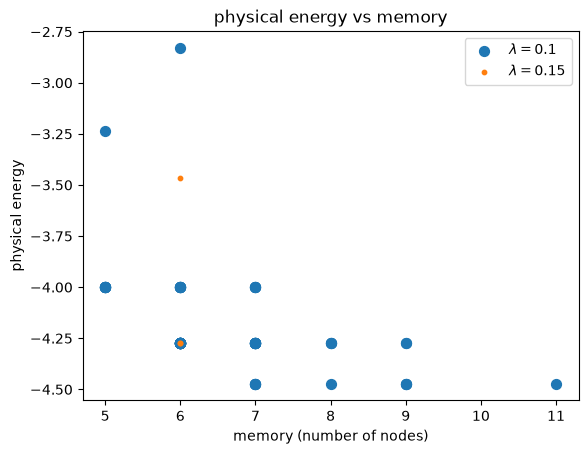

In [164]:
lambdas = np.unique(final_states_df["lambda"])

sizes = np.linspace(50, 10, len(lambdas))

for l, s in zip(lambdas, sizes):
    this_lambda = final_states_df[final_states_df["lambda"] == l]
    plt.scatter(this_lambda["memory"], this_lambda["energy"], s=s, label=f"$\\lambda={l}$")
    # sns.lineplot(x=final_states_df["memory"], y=final_states_df["energy"])
    
plt.title("physical energy vs memory")
plt.xlabel("memory (number of nodes)")
plt.ylabel("physical energy")
plt.legend()
plt.show()

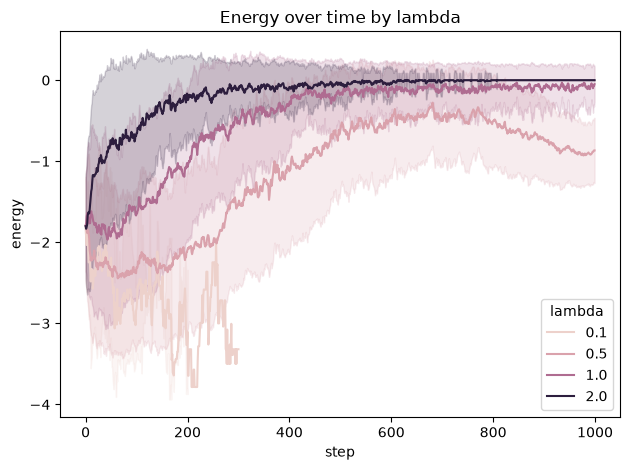

In [150]:
frames = []

for index, row in instances.iterrows():
    out_path = Path(row["out_file"])
    if not out_path.exists():
        continue

    df = pd.read_csv(out_path)
    df = df.reset_index(names="step")  # makes the index an explicit x-axis column
    df["lambda"] = row["lambda"]
    df["run_id"] = index  # tracks individual parallel runs
    frames.append(df)

combined = pd.concat(frames, ignore_index=True)

ax = sns.lineplot(
    data=combined,
    x="step",
    y="energy",
    hue="lambda",
    errorbar="sd",  # or "ci" (default), or None
)
ax.set_title("Energy over time by lambda")
plt.tight_layout()
plt.show()

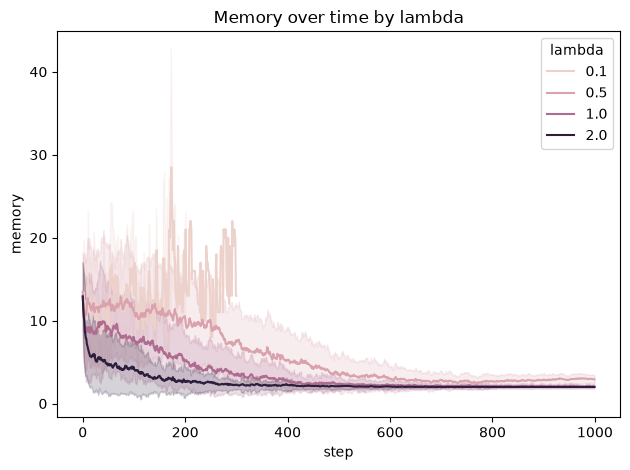

In [154]:
ax = sns.lineplot(
    data=combined,
    x="step",
    y="memory",
    hue="lambda",
    errorbar="sd",  # or "ci" (default), or None
)
ax.set_title("Memory over time by lambda")
plt.tight_layout()
plt.show()

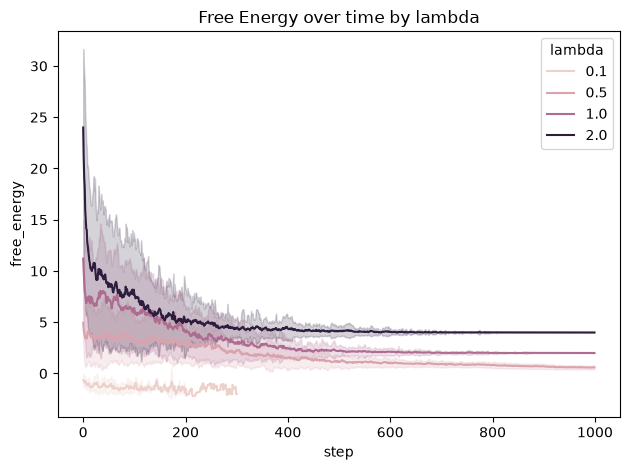

In [155]:
ax = sns.lineplot(
    data=combined,
    x="step",
    y="free_energy",
    hue="lambda",
    errorbar="sd",  # or "ci" (default), or None
)
ax.set_title("Free Energy over time by lambda")
plt.tight_layout()
plt.show()